
========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           4
Dropout:          0.2
Optimizer:        SGD
Adam_LR:        0.001
SGD_LR:        0.001

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Época 01/4 | Train CEL: 2.24689 | Valid CEL: 2.16095 | Train Accuracy: 0.20754 | Valid Accuracy: 0.37300
Época 02/4 | Train CEL: 2.06855 | Valid CEL: 1.92904 | Train Accuracy: 0.35620 | Valid Accuracy: 0.43340
Época 03/4 | Train CEL: 1.81009 | Valid CEL: 1.62527 | Train Accuracy: 0.42344 | Valid Accuracy: 0.54360
Época 04/4 | Train CEL: 1.54345 | Valid CEL: 1.36502 | Train Accuracy: 0.49322 | Valid Accuracy: 0.61840
Training time: 22.36 seconds

Test CEL: 1.36899
Test accuracy: 62.25%

T-shirt/top: 68.80%
Trouser: 91.40%
Pullover: 15.00%
Dress: 63.40%
Coat: 73.00%
Sandal: 64.30%
Shirt: 16.10

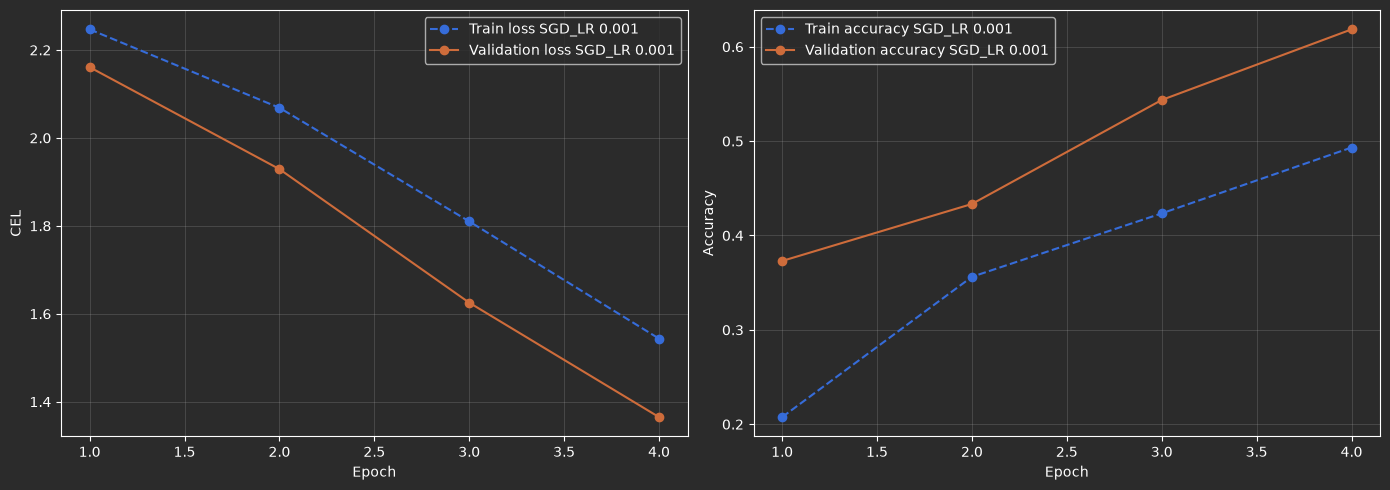

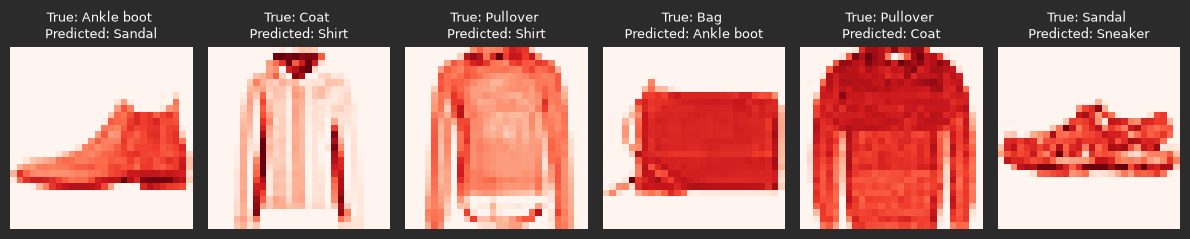

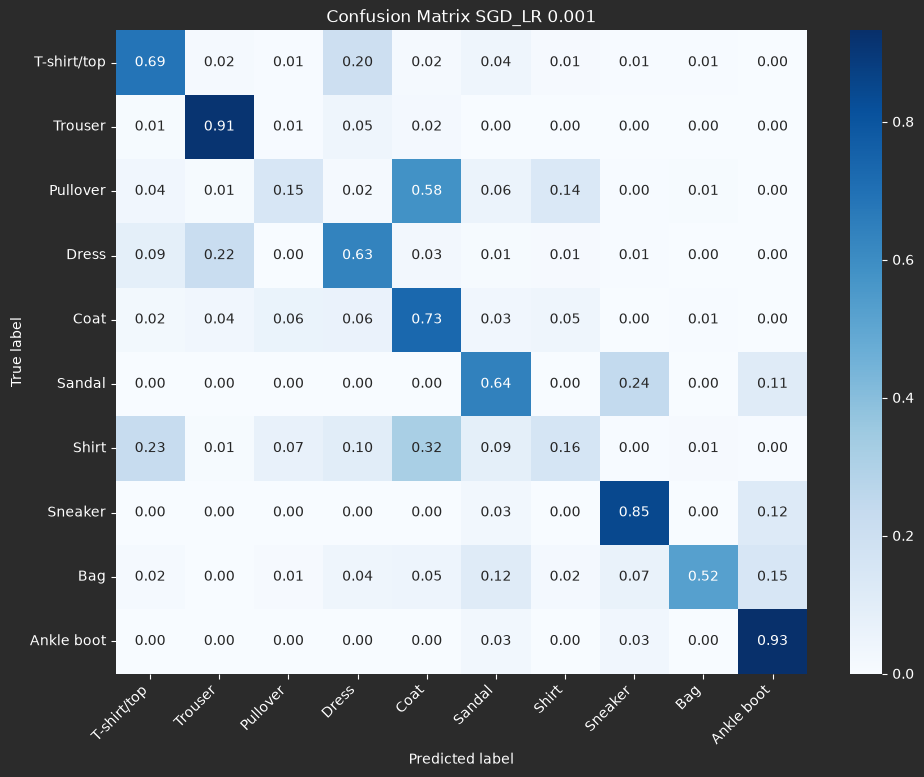


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           4
Dropout:          0.2
Optimizer:        SGD
Adam_LR:        0.001
SGD_LR:        0.001

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Época 01/4 | Train CEL: 2.24689 | Valid CEL: 2.16095 | Train Accuracy: 0.20754 | Valid Accuracy: 0.37300
Época 02/4 | Train CEL: 2.06855 | Valid CEL: 1.92904 | Train Accuracy: 0.35620 | Valid Accuracy: 0.43340
Época 03/4 | Train CEL: 1.81009 | Valid CEL: 1.62527 | Train Accuracy: 0.42344 | Valid Accuracy: 0.54360
Época 04/4 | Train CEL: 1.54345 | Valid CEL: 1.36502 | Train Accuracy: 0.49322 | Valid Accuracy: 0.61840
Training time: 16.82 seconds

Test CEL: 1.36899
Test accuracy: 62.25%

T-shirt/top: 68.80%
Trouser: 91.40%
Pullover: 15.00%
Dress: 63.40%
Coat: 73.00%
Sandal: 64.30%
Shirt: 16.10

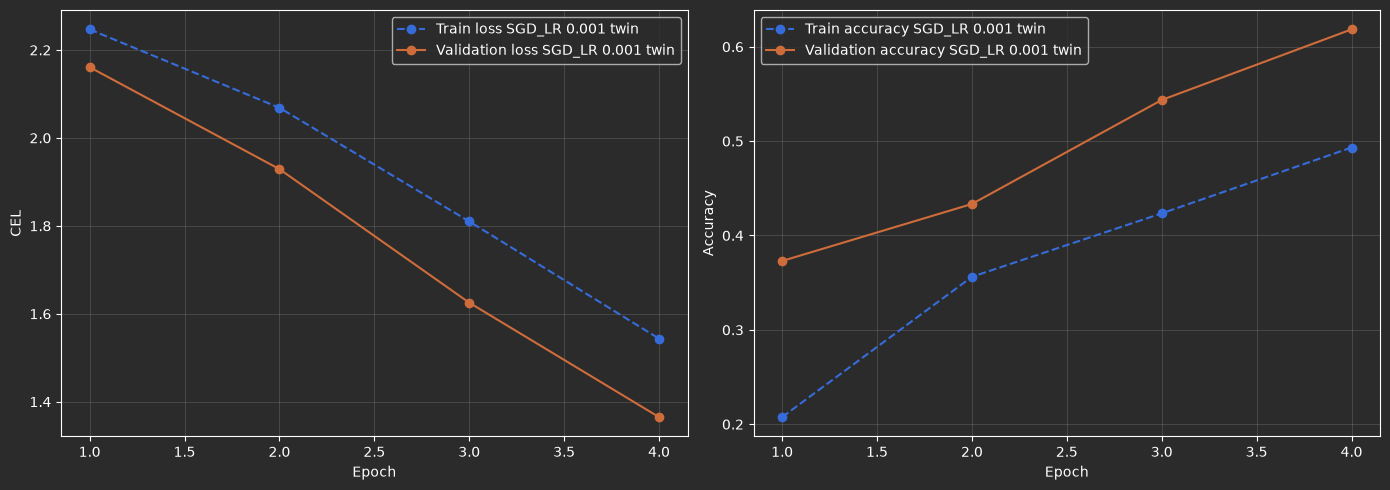

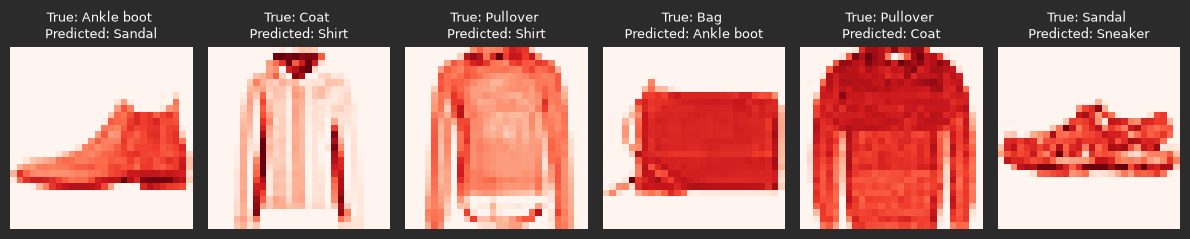

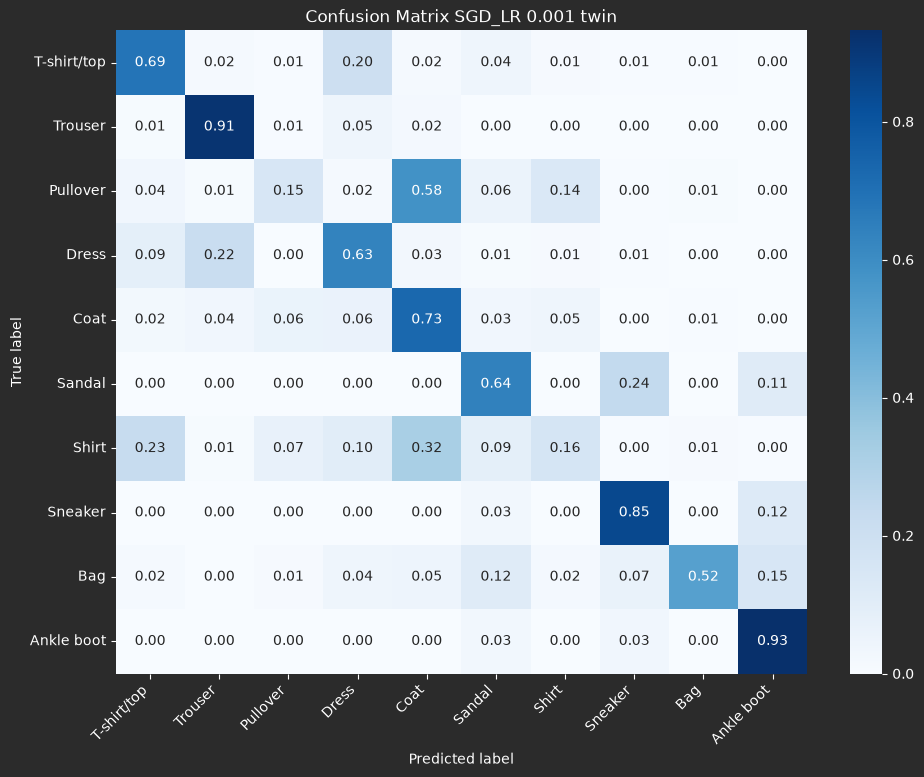


-----------------------------------Results TOGETHER:-----------------------------------



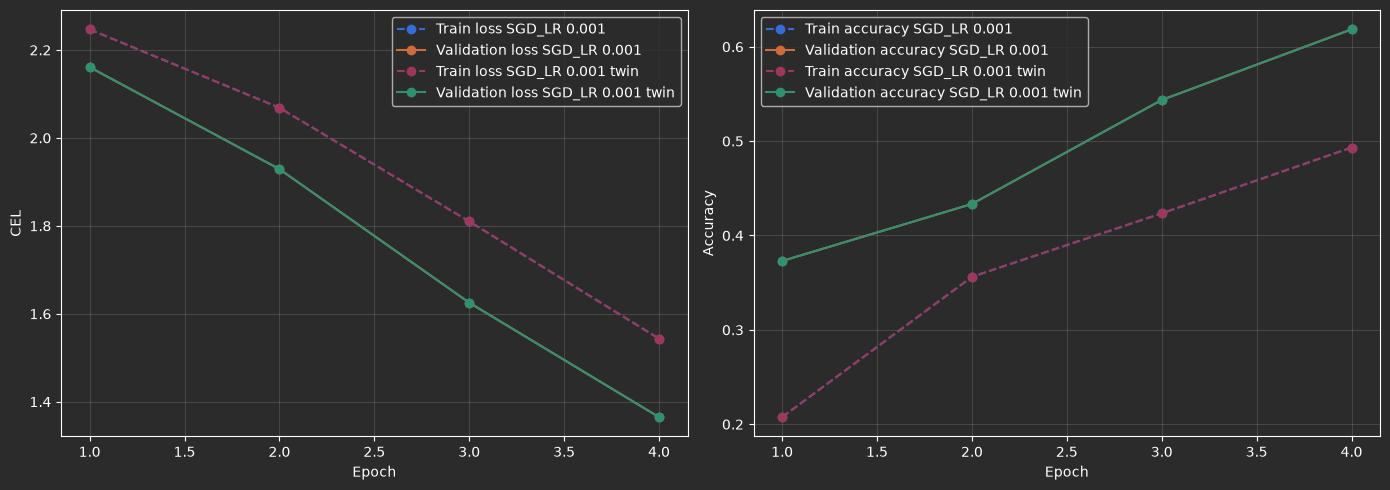

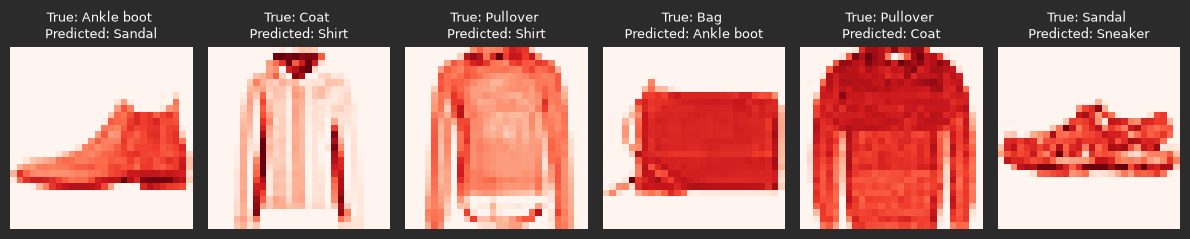

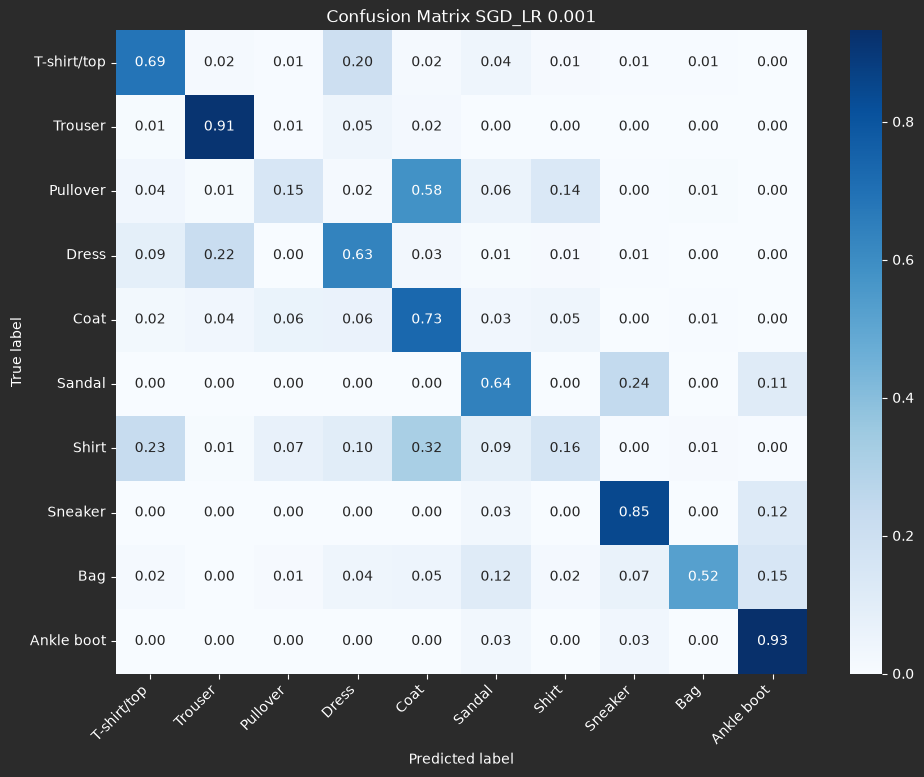

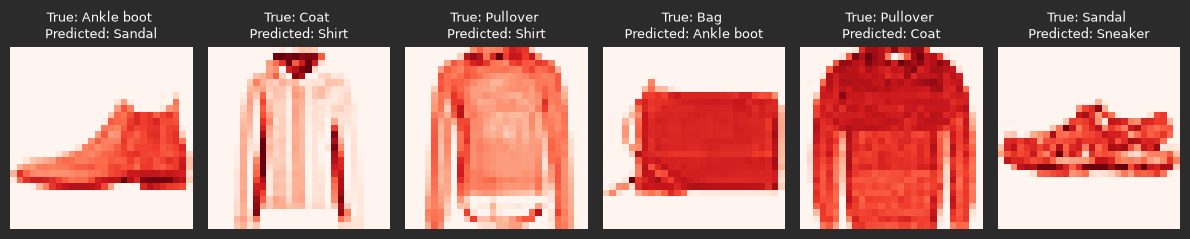

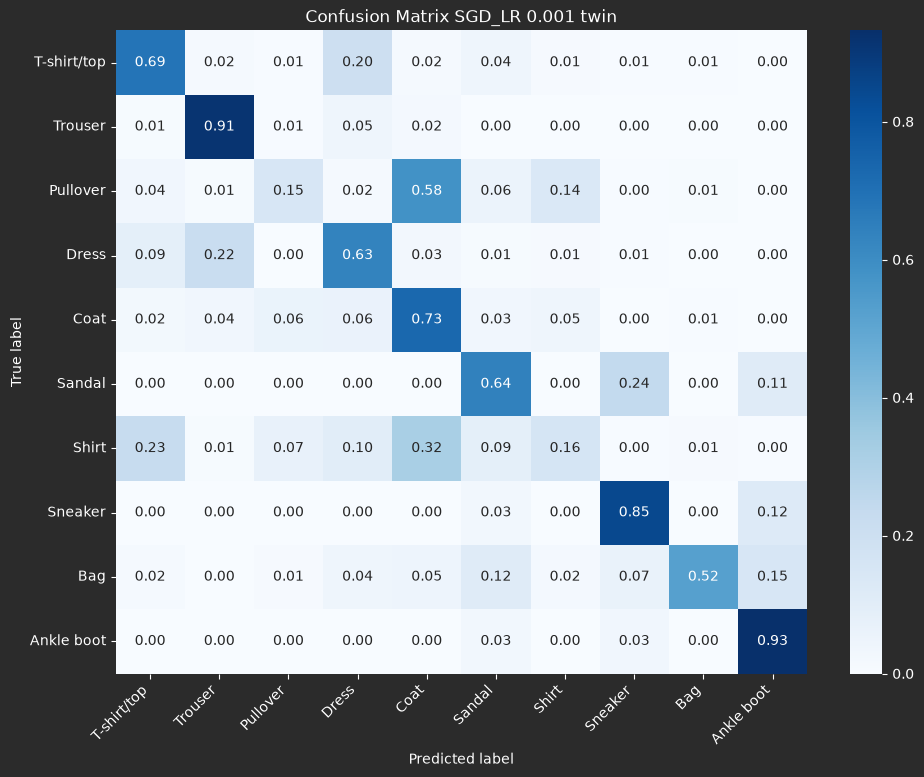

In [1]:
import time

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        adam_lr=config.ADAM_LR,
        sgd_lr=config.SGD_LR
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)

    # Entrenamiento
    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    print(f"Training time: {time.perf_counter() - start:.2f} seconds")
    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================
# showSample=False, showDimentions=False, showUntrained=False, showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True
# runExperiment(Config(dropout_p=0.2, epochs=2)

expies_1 = {
    "SGD_LR 0.001": Config(sgd_lr=0.001, dropout_p=0.2, epochs=30, optimizer_name="SGD", show_sample=False,
                           show_dimentions=False,
                           show_dimentions2=False, show_untrained=False, show_loss=False, show_trained=False,
                           show_epoch_data=True, show_init=True, show_dataset_info=False),
    "SGD_LR 0.01": Config(sgd_lr=0.01, dropout_p=0.2, epochs=30, optimizer_name="SGD", show_sample=False,
                          show_dimentions=False,
                          show_dimentions2=False, show_untrained=False, show_loss=False, show_trained=False,
                          show_epoch_data=True, show_init=True, show_dataset_info=False),
    "SGD_LR 0.1": Config(sgd_lr=0.1, dropout_p=0.2, epochs=30, optimizer_name="SGD", show_sample=False,
                         show_dimentions=False,
                         show_dimentions2=False, show_untrained=False, show_loss=False, show_trained=False,
                         show_epoch_data=True, show_init=True, show_dataset_info=False),
    "Adam_LR 0.0001": Config(adam_lr=0.0001, dropout_p=0.2, epochs=30, optimizer_name="Adam", show_sample=False,
                             show_dimentions=False,
                             show_dimentions2=False, show_untrained=False, show_loss=False, show_trained=False,
                             show_epoch_data=True, show_init=True, show_dataset_info=False),
    "Adam_LR 0.001": Config(adam_lr=0.001, dropout_p=0.2, epochs=30, optimizer_name="Adam", show_sample=False,
                            show_dimentions=False,
                            show_dimentions2=False, show_untrained=False, show_loss=False, show_trained=False,
                            show_epoch_data=True, show_init=True, show_dataset_info=False),
    "Adam_LR 0.01": Config(adam_lr=0.01, dropout_p=0.2, epochs=30, optimizer_name="Adam", show_sample=False,
                           show_dimentions=False,
                           show_dimentions2=False, show_untrained=False, show_loss=False, show_trained=False,
                           show_epoch_data=True, show_init=True, show_dataset_info=False)
}


def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_generator()  # Reset before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        Visualizer.showExpieResults(results)
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")
    Visualizer.showExpieResults(results_together)


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)

pre_run(expies_1, data_loaders)

##TODO si uno quisiera hacer bien las cosas a nivel codigo, tendria estos tipos de test en una seccion de Tests, tambien tendria unit tests
### generator test ####
# data_loaders.reset_generator()
# batches_1 = data_loaders.get_first_batches()
#
# data_loaders.reset_generator()
# batches_2 = data_loaders.get_first_batches()
#
# for i, (b1, b2) in enumerate(zip(batches_1, batches_2)):
#     print(f"Batch {i}: {torch.equal(b1, b2)}") # me tiene que devolver True
### generator test ####

###model test####
# torch.manual_seed(42)
# model_1 = ClassifierMLP()
#
# torch.manual_seed(42)
# model_2 = ClassifierMLP()
#
# print(all(
#     torch.equal(p1, p2) # me tiene que devolver True
#     for p1, p2 in zip(model_1.parameters(), model_2.parameters())
# ))
##### model test ######